# SSR-BKF / SSR-BKNet 统一实验程序（改进版）

本版相对原 `SSR_BKFNet.ipynb` 的主要改动：

1. **一套实现跑全部场景**：`SSRBKF.step` 与 `LearnedFilter.forward` 只在 Cell 4 / Cell 5 各打一次补丁，
   场景差异全部由配置项控制（不再出现 Lorenz 与 Doppler 用两份不同代码的情况）。
2. **解析与学习类方法共用同一份测试数据**（原 Cell 4 重新生成了数据，表中两类方法的测试轨迹不同）。
3. **新增公平基准**：限幅新息 EKF、同比较器预算的 5-bit 预测均匀量化器、限幅新息 KalmanNet。
4. **新增稳健指标与多种子统计**：稳态误差中位数、90% 分位数、失锁率；`seeds=[...]` 给出均值 ± 标准差。
5. **盲自适应启动门控**（饱和率 / 新息一致性 / 预热）与**硬件失配实验**（内部噪声强度、阈值偏置）。
6. **直通梯度三种形式**（`none` / `unit` / `soft`）与 Doppler 的 2×2 消融（相位解调 × 全状态监督）。
7. 每个网络使用独立随机种子；不再修改全局默认 dtype（用上下文管理器局部切换）。

**注意**：本程序未经运行（`ssrbk_*` 模块不在编写环境中），只做过语法检查；
所有对模块内部成员的调用都沿用原 notebook 中已出现过的名字。统一实现后各表数值会与旧结果略有出入，需整体重跑。

In [2]:
# [Cell 1] 环境与公共工具
import copy
import json
import math
import time
from contextlib import contextmanager
from types import SimpleNamespace

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

import ssr_bknet
import ssrbk_filters
import ssrbk_learned
from ssrbk_common import F64, LorenzModel, DopplerModel, bdiag, bmv, qsign, sym
from ssrbk_array import SSRArray
from ssrbk_data import build_scenario
from ssrbk_filters import SSRBKF, calibrate_rlsekf, run_analytic
from ssrbk_learnedv2 import LearnedFilter, eval_loss, seq_loss, run_learned
from ssr_bknet import build_analytic, compute_metrics

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch {torch.__version__} | device: {device}')

SAT_EPS = 1e-6          # 判定"比较器全部同向"的容差


@contextmanager
def default_dtype(dt):
    """局部切换默认浮点类型，退出时恢复（解析滤波用 float64，网络用 float32）。"""
    old = torch.get_default_dtype()
    torch.set_default_dtype(dt)
    try:
        yield
    finally:
        torch.set_default_dtype(old)


def db(x):
    return 10.0 * math.log10(max(float(x), 1e-30))


def t_scalar(x):
    return torch.tensor([x], dtype=F64)


def check(name, val, ref, tol):
    ok = abs(val - ref) <= tol
    print(f'[{"PASS" if ok else "FAIL"}] {name:<46s}: {val:.5f} (参考值 {ref:.5f} ± {tol:g})')
    return ok


def eta_pdf(x, kind):
    """单位方差内部噪声的概率密度。"""
    if kind == 'gauss':
        return torch.exp(-0.5 * x * x) / math.sqrt(2.0 * math.pi)
    if kind == 'logistic':
        s = math.sqrt(3.0) / math.pi
        return 0.25 / s / torch.cosh(x / (2.0 * s)) ** 2
    raise NotImplementedError(f'eta_pdf: 未实现的内部噪声类型 {kind!r}')


def local_slope(u, w, kappa, delta, kind='gauss'):
    """条件均值 w^T g(u;kappa) 对 u 的斜率: (2/kappa) * sum_m w_m f_eta((u-delta_m)/kappa)。
    u, kappa: [...]；w, delta: [M] 或可广播到 [..., M]。"""
    x = (u.unsqueeze(-1) - delta) / kappa.unsqueeze(-1)
    return (2.0 / kappa) * (w * eta_pdf(x, kind)).sum(-1)

PyTorch 2.2.1 | device: cuda


In [3]:
# [Cell 2] 理论自检：Table I 数值、LMMSE 恒等式、闭式矩、Stein 恒等式、局部增益
print('--- 1) 最优孔径因子与最小失真 (高斯输入, 高斯内部噪声) ---')
for N, ks, zs in ((2, 0.249, 0.327), (31, 1.007, 0.103)):
    k, z, _ = SSRArray([0.0], N, 'gauss').kappa_opt(1.0)
    check(f'kappa* (M=1, N={N})', k, ks, 0.01)
    check(f'zeta_min (M=1, N={N})', z, zs, 0.002)
arr_m3 = SSRArray([-0.5, 0.0, 0.5], 21, 'gauss')
k3, z3, w3 = arr_m3.kappa_opt(1.0)
check('kappa* (M=3, N_m=21)', k3, 1.136, 0.02)
check('zeta_min (M=3, N_m=21)', z3, 0.067, 0.002)

print('\n--- 2) LMMSE 权重下: gamma = rho, D = rho(1-rho)v (Logistic 内部噪声) ---')
a_log = SSRArray([-0.5, 0.0, 0.5], 11, 'logistic')
mu, p, C = a_log.moments(t_scalar(0.7), t_scalar(0.9))
w = a_log.lmmse_weights(p, C)
g, _, D = a_log.bussgang(w, mu, p, C, t_scalar(0.7))
rho = float((w * p).sum(-1)[0]) / 0.7
check('gamma - rho', float(g[0]) - rho, 0.0, 1e-8)
check('D - rho(1-rho)v', float(D[0]) - rho * (1 - rho) * 0.7, 0.0, 1e-6)

print('\n--- 3) 高斯-高斯闭式矩: mu_m = 2Phi(-d/s)-1, p_m = 2v/s * phi(d/s), s = sqrt(v+kappa^2) ---')
a_g = SSRArray([-0.5, 0.0, 0.5], 11, 'gauss')
v_t, k_t = 0.7, 0.9
mu, p, C = a_g.moments(t_scalar(v_t), t_scalar(k_t))
s_t = math.sqrt(v_t + k_t ** 2)
Phi = lambda x: 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))
phi = lambda x: math.exp(-0.5 * x * x) / math.sqrt(2.0 * math.pi)
mu_cf = [2.0 * Phi(-d / s_t) - 1.0 for d in (-0.5, 0.0, 0.5)]
p_cf = [2.0 * v_t / s_t * phi(d / s_t) for d in (-0.5, 0.0, 0.5)]
check('max|mu - mu_closed|', max(abs(a - b) for a, b in zip(mu.reshape(-1).tolist(), mu_cf)), 0.0, 1e-6)
check('max|p - p_closed|', max(abs(a - b) for a, b in zip(p.reshape(-1).tolist(), p_cf)), 0.0, 1e-6)

print('\n--- 4) Stein 恒等式: E_u[局部斜率] = w^T p / v；局部增益 gamma_loc(0) > gamma ---')
kst, zst, wst = a_g.kappa_opt(1.0)
wst = torch.as_tensor(wst, dtype=F64).reshape(-1)
delta_g = torch.tensor([-0.5, 0.0, 0.5], dtype=F64)
xs, ws = np.polynomial.hermite_e.hermegauss(201)
ws = torch.tensor(ws / ws.sum(), dtype=F64)
for v_t in (0.3, 1.0, 2.0):
    u_n = torch.tensor(math.sqrt(v_t) * xs, dtype=F64)
    lhs = float((ws * local_slope(u_n, wst, torch.full_like(u_n, kst), delta_g, 'gauss')).sum())
    mu, p, C = a_g.moments(t_scalar(v_t), t_scalar(kst))
    check(f'E[slope] - w^T p / v  (v={v_t})', lhs - float((wst * p.reshape(-1)).sum()) / v_t, 0.0, 1e-5)
mu, p, C = a_g.moments(t_scalar(1.0), t_scalar(kst))
g_s, _, D_s = a_g.bussgang(wst.unsqueeze(0), mu, p, C, t_scalar(1.0))
g_l, _, D_l = a_g.taylor(wst.unsqueeze(0), t_scalar(kst))
g_s, D_s = float(g_s.reshape(-1)[0]), float(D_s.reshape(-1)[0])
g_l, D_l = float(g_l.reshape(-1)[0]), float(D_l.reshape(-1)[0])
check('gamma (矩匹配, kappa*)', g_s, 0.9060, 0.002)
check('gamma_loc(0) (局部增益)', g_l, 1.2705, 0.005)
check('D/gamma^2 (矩匹配)', D_s / g_s ** 2, 0.1037, 0.002)
check('D/gamma^2 (局部增益)', D_l / g_l ** 2, 0.0429, 0.002)

--- 1) 最优孔径因子与最小失真 (高斯输入, 高斯内部噪声) ---
[PASS] kappa* (M=1, N=2)                             : 0.24886 (参考值 0.24900 ± 0.01)
[PASS] zeta_min (M=1, N=2)                           : 0.32698 (参考值 0.32700 ± 0.002)
[PASS] kappa* (M=1, N=31)                            : 1.00734 (参考值 1.00700 ± 0.01)
[PASS] zeta_min (M=1, N=31)                          : 0.10294 (参考值 0.10300 ± 0.002)
[PASS] kappa* (M=3, N_m=21)                          : 1.13578 (参考值 1.13600 ± 0.02)
[PASS] zeta_min (M=3, N_m=21)                        : 0.06676 (参考值 0.06700 ± 0.002)

--- 2) LMMSE 权重下: gamma = rho, D = rho(1-rho)v (Logistic 内部噪声) ---
[PASS] gamma - rho                                   : 0.00000 (参考值 0.00000 ± 1e-08)
[PASS] D - rho(1-rho)v                               : -0.00000 (参考值 0.00000 ± 1e-06)

--- 3) 高斯-高斯闭式矩: mu_m = 2Phi(-d/s)-1, p_m = 2v/s * phi(d/s), s = sqrt(v+kappa^2) ---
[PASS] max|mu - mu_closed|                           : 0.00000 (参考值 0.00000 ± 1e-06)
[PASS] max|p - p_closed|                     

True

In [4]:
# [Cell 3] 配置生成器（原有字段不变；"本版新增"一段是新加的开关）
def make_config(**overrides):
    cfg = SimpleNamespace(
        scenario='lorenz', seed=0, device=str(device), threads=0, out='results',
        tr_window=100,
        n_train=1000, n_cv=100, n_test=50, T_train=100, T_test=2000, burn=500,
        dt=0.02, J_data=5, J_model=5, q2=1e-3, r2=1e-1, rot_deg=0.0,
        noise='gauss', alpha=1.5, noise_scale=0.0, mix_eps=0.05, mix_kappa=10.0, clip=1e4,
        init_mismatch=0.0, train_mismatch=-1.0, P0='informed', P0_small=1e-3, P0_floor=1e-3,
        groups=3, per_group=11, offset_span=0.5, offsets=[-0.5, 0.0, 0.5],
        eta='gauss', n_quad=401,
        scale_ref='hybrid', kappa_mode='opt', kappa=1.0,
        mu_eta=1.0, mu_s=0.1, mu_sat=0.3, s_const=0.0, inflate=False,
        rls_target='smoothed', lag=10, lam_w=0.1, lam_f=0.999, rls_P0=10.0,
        huber=1.345, rls_init='lmmse', Q_kappa=1e-3, R_kappa=1.0, P_kappa0=2.0,
        kappa_min=0.05, kappa_max=10.0,
        dither=-1.0, cal_samples=20000,
        iters=400, batch=32, lr=1e-3, wd=1e-4, in_mult=5, out_mult=40,
        cv_every=50, clip_grad=10.0, st_grad=True, learn_w=True,
        nclt_npz='', nclt_hz=1.0,
        dop_dt=0.01, dop_amp=1.0, dop_qphi=1e-4, dop_qf=1e-6, dop_qfd=1e-4,
        dop_r2=1.0, dop_frange=5.0, dop_fdstd=0.1,

        # ======================= 本版新增 =======================
        # --- 解析 SSR-BKF ---
        c_sat=15.0,            # 全饱和时量化噪声方差放大 (1 + c_sat)；0 = 关闭
        rls_renorm=True,       # RLS 权重范数对齐到当前 LMMSE 权重范数
        adapt_gate=True,       # 盲自适应 (M-RLS / kappa-EKF) 启动门控
        adapt_warmup=50,       # 前若干步不更新
        adapt_sat_max=0.05,    # 饱和率滑动平均上限
        adapt_nis_max=3.0,     # 归一化新息平方 e^2/S 的滑动平均上限 (锁定时约为 1)
        adapt_umax=3.0,        # 平滑参考 |u| 上限 (超出孔径的样本不用)
        gate_ema=0.05,         # 上述滑动平均的步长
        kappa_mismatch=1.0,    # 硬件失配：实际内部噪声强度 = kappa_mismatch × 标称值
        thr_bias=0.0,          # 硬件失配：全部阈值的公共偏置 (以孔径尺度为单位)
        # --- 新增解析基准 ---
        clip_c=3.0,            # 限幅新息 EKF：限幅点 = clip_c × 孔径尺度
        quant_bits=5,          # 预测均匀量化器位数 (2^b - 1 个比较器)
        quant_range=3.0,       # 均匀量化器满量程 = ± quant_range × 孔径尺度
        # --- 学习类滤波器 ---
        ste_mode='unit',       # st_grad=True 时的直通梯度: 'none' | 'unit' | 'soft'
        loss_mode='eval',      # 'eval': 只监督 eval_idx；'full': 全状态加权
        state_w=None,          # loss_mode='full' 时各状态分量的权重
        phase_demod=True,      # 多普勒场景的相位解调投影
        dec_scale='aperture',  # 解码所乘尺度: 'aperture' (随孔径) | 'fixed' (固定 a0，全饱和减半)
        ap_mult=(1e-2, 1e2),   # 孔径相对初始尺度 a0 的上下限
        state_clip=100.0,      # Lorenz 状态限幅 (防 float32 溢出)；其他场景不限幅
        clip_innov=3.0,        # 'knet_clip' 的新息限幅点 (× 稳健尺度)
    )
    for k, v in overrides.items():
        if not hasattr(cfg, k):
            raise KeyError(f'make_config: 未知配置项 {k!r}')
        setattr(cfg, k, v)
    if cfg.train_mismatch < 0:
        cfg.train_mismatch = cfg.init_mismatch
    return cfg


def with_seed(cfg, seed):
    c = SimpleNamespace(**vars(cfg))
    c.seed = seed
    return c


# 标准阵列与前期 RLS-EKF 在线校准
cfg_nom = make_config()
with default_dtype(torch.float64):
    arr = SSRArray(cfg_nom.offsets, cfg_nom.per_group, cfg_nom.eta, cfg_nom.n_quad)
    kstar, zstar, wstar = arr.kappa_opt(1.0)
    print(f'SSR 阵列 (M={arr.M}, N_m={arr.per_group}, N={arr.N}):')
    print(f'  kappa* = {kstar:.4f} | zeta* = {zstar:.4f} (线性可解释方差比例 rho = {100 * (1 - zstar):.1f}%)')
    print(f'  w*     = {[round(x, 4) for x in wstar.tolist()]}')

    gen = torch.Generator().manual_seed(cfg_nom.seed)
    scen_nom, train_nom, cv_nom, test_nom = build_scenario(cfg_nom, arr, gen)
    cal_nom = calibrate_rlsekf(arr, train_nom.y, train_nom.eta, cfg_nom.cal_samples)
    print('\n[固定阈值 RLS-EKF 在线校准, Lorenz 观测]')
    print(f'  sig_norm: {[round(x, 4) for x in cal_nom["sig_norm"].tolist()]}  (kappa* = {kstar:.4f})')
    print(f'  w_norm  :\n{cal_nom["w_norm"].numpy().round(4)}')

    # 对照：把输入换成同均值、同方差的高斯白序列。
    # 若 sig_norm 仍明显高于 kappa*（理论预测约 1.07），偏差来自 kappa 递推本身（缺少二项涨落项的梯度）；
    # 若回到 kappa* 附近，则偏差来自 Lorenz 边缘分布的非高斯性。
    g_ctl = torch.Generator().manual_seed(123)
    y_std = train_nom.y.std(dim=(0, 1), keepdim=True)
    y_mean = train_nom.y.mean(dim=(0, 1), keepdim=True)
    y_gauss = torch.randn(train_nom.y.shape, generator=g_ctl, dtype=train_nom.y.dtype) * y_std + y_mean
    cal_g = calibrate_rlsekf(arr, y_gauss, train_nom.eta, cfg_nom.cal_samples)
    print('\n[同一校准程序, 高斯输入对照]')
    print(f'  sig_norm: {[round(x, 4) for x in cal_g["sig_norm"].tolist()]}  (kappa* = {kstar:.4f}, 精确参考下的平均场不动点 ≈ 1.071)')
    print(f'  w_norm  :\n{cal_g["w_norm"].numpy().round(4)}')

SSR 阵列 (M=3, N_m=11, N=33):
  kappa* = 0.9149 | zeta* = 0.0940 (线性可解释方差比例 rho = 90.6%)
  w*     = [0.5635, 0.4862, 0.5635]

[固定阈值 RLS-EKF 在线校准, Lorenz 观测]
  sig_norm: [0.9034, 1.0061, 1.1327]  (kappa* = 0.9149)
  w_norm  :
[[0.5301 0.478  0.518 ]
 [0.5639 0.5048 0.5627]
 [0.5967 0.5583 0.5943]]

[同一校准程序, 高斯输入对照]
  sig_norm: [1.0154, 0.985, 0.9573]  (kappa* = 0.9149, 精确参考下的平均场不动点 ≈ 1.071)
  w_norm  :
[[0.5724 0.5053 0.5674]
 [0.5804 0.5232 0.5798]
 [0.571  0.5048 0.5657]]


In [5]:
# [Cell 4] 统一的解析 SSR-BKF 单步递推（全部场景共用；只打一次补丁）
if not hasattr(SSRBKF, '_orig_step'):                 # 保存模块原版，重复执行本 Cell 也不会丢
    SSRBKF._orig_step = SSRBKF.step
    SSRBKF._orig_update_scale = SSRBKF._update_scale


def ssr_update_scale(self, e_t, sg, sat=None):
    """乘性运行中位数跟踪：非饱和时收敛到 |e| 的中位数；全饱和时每步放大 exp(mu_sat + mu_s/2)。"""
    cfg = self.cfg
    if sat is None:
        sat = (sg.mean(-1).abs() >= 1.0 - SAT_EPS).to(e_t.dtype)
    ind = (e_t.abs() > self.m_rob).to(e_t.dtype)
    self.m_rob = (self.m_rob * torch.exp(cfg.mu_s * (ind - 0.5) + cfg.mu_sat * sat)).clamp(1e-9, 1e9)


def ssr_step(self, t, y, eta):
    cfg, arr = self.cfg, self.arr
    front = getattr(self, 'front', 'ssr')              # 'ssr' | 'analog_clip' | 'uniform'
    c_sat = float(getattr(cfg, 'c_sat', 0.0))
    k_mis = float(getattr(cfg, 'kappa_mismatch', 1.0))
    thr_b = float(getattr(cfg, 'thr_bias', 0.0))

    # ---------- 预测 ----------
    zp, Sp, Fj = self.predict()
    yp, H, P = self.meas_prior(zp, Sp)
    if cfg.inflate and cfg.scale_ref in ('robust', 'hybrid'):
        # 协方差匹配：稳健尺度的平方超出 (H Sigma H^T + R + q) 的部分按比例膨胀先验协方差
        HSH = (bdiag(P) - self.Rd).clamp_min(1e-12)
        excess = (self.m_rob / 0.6745) ** 2 - self.Rd - self.q_var
        lam = (excess / HSH).clamp_min(1.0).amax(-1)
        Sp = Sp * lam[:, None, None]
        yp, H, P = self.meas_prior(zp, Sp)
    Pd = bdiag(P)

    # ---------- 孔径尺度 ----------
    s_ref = self._scale_reference(Pd)
    self.s_used = s_ref.clone() if self.s_used is None else self.s_used + cfg.mu_eta * (s_ref - self.s_used)
    scale = self.s_used.clamp_min(1e-9)
    kappa = self.kappa

    # ---------- 比较器阵列（可带硬件失配；解码端仍按标称 kappa 计算） ----------
    y_in = y - thr_b * scale if thr_b != 0.0 else y
    sg = arr.bits(y_in, yp, scale, kappa * k_mis, eta)
    sat = (sg.mean(-1).abs() >= 1.0 - SAT_EPS).to(scale.dtype)

    # ---------- 解码权重与 Bussgang 参数 ----------
    v = (Pd / scale ** 2).clamp(1e-6, 25.0)
    mu, p, C = arr.moments(v, kappa)
    w_lmmse = arr.lmmse_weights(p, C)
    if self.weight_mode == 'lmmse':
        w = w_lmmse
    elif self.weight_mode == 'rls':
        w = self.w
        if getattr(cfg, 'rls_renorm', True):
            w = w * (w_lmmse.norm(dim=-1, keepdim=True) / w.norm(dim=-1, keepdim=True).clamp_min(1e-9))
    else:
        w = torch.full_like(sg, 1.0 / arr.M)
    if self.gain_mode == 'stat':
        gam, mean, D = arr.bussgang(w, mu, p, C, v)
    else:
        gam, mean, D = arr.taylor(w, kappa)
    gam = gam.clamp_min(1e-4)

    # ---------- 伪残差与量化噪声方差 ----------
    if front == 'ssr':
        e_t = scale * ((w * sg).sum(-1) - mean) / gam
        q = scale ** 2 * D / gam ** 2
    elif front == 'analog_clip':
        # 基准：全精度新息在 ±clip_c×scale 处限幅（稳健 EKF）
        c = float(getattr(cfg, 'clip_c', 3.0))
        u = (y - yp) / scale
        e_t = scale * u.clamp(-c, c)
        q = torch.zeros_like(scale)
        sat = (u.abs() >= c).to(scale.dtype)
    elif front == 'uniform':
        # 基准：b 位预测均匀量化器 (mid-rise)，量程 ±quant_range×scale，无内部噪声
        nb = int(getattr(cfg, 'quant_bits', 5))
        c = float(getattr(cfg, 'quant_range', 3.0))
        step_q = 2.0 * c / (2 ** nb)
        u = (y - yp) / scale
        code = torch.floor(u / step_q).clamp(-(2 ** (nb - 1)), 2 ** (nb - 1) - 1)
        e_t = scale * (code + 0.5) * step_q
        q = scale ** 2 * step_q ** 2 / 12.0
        sat = (u.abs() >= c).to(scale.dtype)
    else:
        raise ValueError(f'未知前端类型 {front!r}')
    # 全饱和时伪残差只是截断值，放大其噪声方差以降低权重
    self.q_var = q * (1.0 + c_sat * sat)

    # ---------- 卡尔曼更新 ----------
    S = sym(P + torch.diag_embed(self.q_var))
    K = self.gain(Sp, H, S)
    self.finish(zp + bmv(K, e_t), Sp - K @ S @ K.transpose(-1, -2))
    self._update_scale(e_t, sg, sat)
    self.hist.append(dict(zp=zp, Sp=Sp, F=Fj, z=self.z, S=self.S, sg=sg, scale=scale,
                          kappa=kappa.clone(), w=w.clone(), yp=yp))

    # ---------- 锁定指示量（盲自适应门控用） ----------
    a_g = float(getattr(cfg, 'gate_ema', 0.05))
    nis = e_t ** 2 / bdiag(S).clamp_min(1e-12)
    if getattr(self, '_sat_ema', None) is None or self._sat_ema.shape != sat.shape:
        self._sat_ema = torch.zeros_like(sat)
        self._nis_ema = torch.ones_like(sat)
    self._sat_ema = self._sat_ema + a_g * (sat - self._sat_ema)
    self._nis_ema = self._nis_ema + a_g * (nis.clamp(max=100.0) - self._nis_ema)

    # ---------- 盲自适应：固定滞后平滑参考 + M-RLS + kappa-EKF ----------
    tgt = self._target(t)
    if tgt is not None:
        ent, d = tgt
        u_t = d / ent['scale']
        gate = bool(getattr(cfg, 'adapt_gate', False))
        ok = None
        if gate:
            ok = ((self._sat_ema < cfg.adapt_sat_max)
                  & (self._nis_ema < cfg.adapt_nis_max)
                  & (ent['sg'].mean(-1).abs() < 1.0 - SAT_EPS)
                  & (u_t.abs() <= cfg.adapt_umax))
            if t < cfg.adapt_warmup:
                ok = torch.zeros_like(ok)
        if self.weight_mode == 'rls':
            w_old = self.w.clone()
            self._rls(ent['sg'], u_t)
            if gate and self.w.shape[:-1] == ok.shape:        # 逐 (轨迹, 维度) 回退未通过门控的更新
                self.w = torch.where(ok.unsqueeze(-1), self.w, w_old)
            elif gate and not bool(ok.all()):
                self.w = w_old
        if self.kappa_mode == 'ekf':
            k_old = self.kappa.clone()
            self._kappa_ekf(ent, u_t)
            if gate and self.kappa.shape == ok.shape:
                self.kappa = torch.where(ok, self.kappa, k_old)
            elif gate and not bool(ok.all()):
                self.kappa = k_old
    return self.z


ssr_bknet.SSRBKF = ssrbk_filters.SSRBKF                      # 消除 reload 残留的类对象不一致
for _cls in {SSRBKF, ssrbk_filters.SSRBKF, ssr_bknet.SSRBKF}:
    _cls._update_scale = ssr_update_scale
    _cls.step = ssr_step


def set_label(obj, label):
    obj._label = label


def get_label(obj):
    return getattr(obj, '_label', None) or obj.name


def build_filter(name, scen, arr_l, cfg, cal):
    """在 build_analytic 之上增加两个同框架的公平基准。"""
    if name == 'ekf_clip':
        f = build_analytic('ssrbkf', scen, arr_l, cfg, cal)
        f.front = 'analog_clip'
        set_label(f, f'EKF + clipped innovation (c={cfg.clip_c:g})')
    elif name == 'uq_agc':
        f = build_analytic('ssrbkf', scen, arr_l, cfg, cal)
        f.front = 'uniform'
        set_label(f, f'Predictive {cfg.quant_bits}-bit uniform + adaptive range (L={2 ** cfg.quant_bits - 1})')
    else:
        f = build_analytic(name, scen, arr_l, cfg, cal)
    return f


ANALYTIC = [
    'ekf',            # 全精度 EKF
    'ekf_clip',       # 全精度 EKF + 限幅新息（稳健基准，新增）
    'uq_agc',         # 5-bit 预测均匀量化器 + 自适应量程（同比较器预算基准，新增）
    'bkf',            # Jung et al. 单比较器 BKF
    'bkf_dither',     # 33 比较器固定抖动 rBKF（同比较器预算）
    'rlsekf',         # 前期固定阈值 RLS-EKF
    'ssrbkf_1dof',    # 消融：仅位置
    'ssrbkf',         # 位置 + 尺度，矩匹配增益
    'ssrbkf_rls',     # + M-RLS / kappa-EKF（平滑参考）
    'ssrbkf_taylor',  # 位置 + 尺度，局部增益
]

In [6]:
# [Cell 5] 统一的学习类滤波器前向传播与训练函数
LEARNED_SPECS = {
    'knet':      dict(kind='knet'),
    'knet_clip': dict(kind='knet', clip=True, label='KalmanNet + clipped innovation'),
    'bknet':     dict(kind='bknet'),
    'ssrbknet':  dict(kind='ssrbknet'),
}
_OPT_KEYS = ('ste_mode', 'loss_mode', 'state_w', 'phase_demod', 'dec_scale', 'ap_mult',
             'state_clip', 'clip_innov', 'st_grad', 'eta', 'offsets', 'mu_s', 'mu_sat')


def make_learned(key, scen, arr_l, cfg, train):
    spec = dict(LEARNED_SPECS[key])
    kind = spec.pop('kind')
    label = spec.pop('label', None)
    lf = LearnedFilter(scen.model_filt, kind, arr=arr_l, cfg=cfg,
                       Sig0=torch.diag(train.P0d.mean(0)),
                       in_mult=cfg.in_mult, out_mult=cfg.out_mult).float()
    opt = {k: getattr(cfg, k) for k in _OPT_KEYS}
    opt['clip'] = False
    opt.update(spec)                                   # 规格里的项覆盖 cfg（用于消融）
    lf.opt = SimpleNamespace(**opt)
    set_label(lf, label or lf.name)
    return lf


def ssr_forward(self, y, eta, z0, P0d, st_grad=False):
    mdl, kind = self.model, self.kind
    o = self.opt
    is_lorenz = isinstance(mdl, LorenzModel)
    is_doppler = isinstance(mdl, DopplerModel)
    B, T, _ = y.shape
    self.net.init_hidden(B)
    z_post = z_post_prev = z_prior_prev = z0
    with torch.no_grad():
        h0 = mdl.h(z0)
    prev = torch.zeros_like(h0) if kind == 'bknet' else h0
    lo, hi = o.ap_mult
    need_scale = (kind == 'ssrbknet') or (kind == 'knet' and o.clip)
    if need_scale:
        with torch.no_grad():
            H0 = mdl.H(z0)
            P0 = H0 @ torch.diag_embed(P0d) @ H0.transpose(-1, -2) + mdl.Rm(z0)
            scale0 = bdiag(P0).clamp_min(1e-12).sqrt()
            m_rob = 0.6745 * scale0
            m_lo, m_hi = lo * 0.6745 * scale0, hi * 0.6745 * scale0
    if kind == 'ssrbknet':
        gam = (self.w * self.p_vec).sum().clamp_min(0.1)       # learn_w 时防止除零
        mean = (self.w * self.mu_vec).sum()
        with torch.no_grad():
            kap = torch.full_like(scale0, self.kstar)
            delta = torch.as_tensor(o.offsets, dtype=y.dtype, device=y.device)

    outs = []
    for t in range(T):
        z_in = z_post.clamp(-o.state_clip, o.state_clip) if (is_lorenz and o.state_clip) else z_post
        z_prior = mdl.f(z_in)
        y_pred = mdl.h(z_prior)
        extra = None

        if kind == 'knet':
            obs = y[:, t]
            raw = obs - y_pred
            if o.clip:
                # 稳健基准：新息在 ±clip_innov×稳健尺度 处限幅，尺度用同样的运行中位数跟踪
                with torch.no_grad():
                    lim = o.clip_innov * m_rob / 0.6745
                upd = torch.maximum(torch.minimum(raw, lim), -lim)
                xt = y_pred.detach() + upd
                obs_diff, innov = xt - prev, upd
                prev = xt.detach()
                with torch.no_grad():
                    ind = (raw.abs() > m_rob).to(raw.dtype)
                    sat_k = (raw.abs() >= lim).to(raw.dtype)
                    m_rob = torch.maximum(torch.minimum(
                        m_rob * torch.exp(o.mu_s * (ind - 0.5) + o.mu_sat * sat_k), m_hi), m_lo)
            else:
                upd = raw
                obs_diff, innov, prev = obs - prev, upd, obs

        elif kind == 'bknet':
            with torch.no_grad():
                r = qsign(y[:, t] - y_pred)
            upd = r
            obs_diff, innov, prev = r - prev, r, r

        else:  # ssrbknet
            with torch.no_grad():
                scale = torch.maximum(torch.minimum(m_rob / 0.6745, hi * scale0), lo * scale0)
                sg = self.arr.bits(y[:, t], y_pred, scale, kap, eta[:, t])
                sat_all = (sg.mean(-1).abs() >= 1.0 - SAT_EPS).to(sg.dtype)
                dec = scale if o.dec_scale == 'aperture' else scale0 * (1.0 - 0.5 * sat_all)
            u_hat = ((self.w * sg).sum(-1) - mean) / gam          # 归一化伪残差（对 w 可导）
            upd = dec * u_hat
            if st_grad and o.ste_mode != 'none':
                if o.ste_mode == 'soft':
                    # 软直通：反向斜率取条件均值的真实斜率 gamma_loc(u_hat)/gamma，饱和区自动趋零
                    with torch.no_grad():
                        slope = (dec / scale) * local_slope(u_hat, self.w, kap, delta, o.eta) / gam
                        slope = slope.clamp(0.0, 3.0)
                else:
                    slope = 1.0                                   # 单位斜率 = 真实斜率的先验平均
                upd = upd + slope * (y_pred.detach() - y_pred)
            xt = y_pred.detach() + upd
            obs_diff, innov = xt - prev, upd
            prev = xt.detach()
            with torch.no_grad():
                sat_g = (sg.abs() >= 1.0 - SAT_EPS).to(sg.dtype)
                extra = torch.cat([torch.log(scale / scale0).clamp(-5.0, 5.0),   # 对数孔径张开比
                                   sat_g.mean(-1),                               # 组饱和率
                                   (upd / scale).clamp(-5.0, 5.0)], -1)          # 归一化伪残差
                raw_e = scale * u_hat
                ind = (raw_e.abs() > m_rob).to(sg.dtype)
                m_rob = torch.maximum(torch.minimum(
                    m_rob * torch.exp(o.mu_s * (ind - 0.5) + o.mu_sat * sat_all), m_hi), m_lo)

        if is_doppler and o.phase_demod:
            # 正交投影 U(phi_hat) = [[-sin, cos], [cos, sin]]：第 1 分量为切向（鉴相），第 2 分量为径向
            c_phi, s_phi = y_pred[:, 0] / mdl.amp, y_pred[:, 1] / mdl.amp
            upd = torch.stack([-s_phi * upd[:, 0] + c_phi * upd[:, 1],
                               c_phi * upd[:, 0] + s_phi * upd[:, 1]], dim=-1)
            cd, sd = c_phi.detach(), s_phi.detach()
            obs_diff = torch.stack([-sd * obs_diff[:, 0] + cd * obs_diff[:, 1],
                                    cd * obs_diff[:, 0] + sd * obs_diff[:, 1]], dim=-1)
            innov = upd

        K = self.net(obs_diff, innov, z_post - z_post_prev, z_post - z_prior_prev, extra)
        z_new = z_prior + bmv(K, upd)
        z_post_prev, z_prior_prev, z_post = z_post, z_prior, z_new
        outs.append(z_post)
    return torch.stack(outs, 1)


ssr_bknet.LearnedFilter = ssrbk_learned.LearnedFilter
for _cls in {LearnedFilter, ssrbk_learned.LearnedFilter, ssr_bknet.LearnedFilter}:
    _cls.forward = ssr_forward


def train_filter(lf, train, cv, idx, cfg, dev):
    """Adam + 梯度裁剪 + 损失/梯度有限性守卫 + 按验证集保留最优权重。"""
    o = lf.opt
    lf.to(dev)
    tr, cvd = train.to(dev, torch.float32), cv.to(dev, torch.float32)
    optim = torch.optim.Adam(lf.parameters(), lr=cfg.lr, weight_decay=cfg.wd)
    best, best_state = float('inf'), copy.deepcopy(lf.state_dict())
    sw = None
    if o.loss_mode == 'full':
        sw = torch.ones(tr.z.shape[-1]) if o.state_w is None else torch.tensor(o.state_w, dtype=torch.float32)
        sw = sw.to(dev)
    name, n_skip, hist, t0 = get_label(lf), 0, [], time.time()
    for it in range(1, cfg.iters + 1):
        lf.train()
        bi = torch.randint(0, tr.B, (min(cfg.batch, tr.B),)).to(dev)
        b = tr.slice(bi)
        xh = lf(b.y, b.eta, b.z0, b.P0d, st_grad=o.st_grad)
        if sw is None:
            loss = seq_loss(xh, b.z, idx)
        else:
            loss = (((xh - b.z) ** 2) * sw).sum(-1).mean()
        optim.zero_grad(set_to_none=True)
        stepped = False
        if torch.isfinite(loss) and loss.item() < 1e6:
            loss.backward()
            gn = nn.utils.clip_grad_norm_(lf.parameters(), cfg.clip_grad)
            if torch.isfinite(gn):                    # 只有梯度也有限才更新
                optim.step()
                stepped = True
        if not stepped:
            n_skip += 1
            lf.load_state_dict(best_state)
        if it % cfg.cv_every == 0 or it == cfg.iters:
            cvl = eval_loss(lf, cvd, idx)
            if cvl < best:
                best, best_state = cvl, copy.deepcopy(lf.state_dict())
            tr_db = db(loss) if torch.isfinite(loss) else float('nan')
            hist.append((it, tr_db, db(cvl)))
            print(f'    [{name}] it {it:5d}  train {tr_db:7.2f} dB  cv {db(cvl):7.2f} dB'
                  f'  (best {db(best):7.2f} dB, skipped {n_skip}, {time.time() - t0:.0f} s)')
    lf.load_state_dict(best_state)
    return best, hist

In [7]:
# [Cell 6] 指标、单次实验与多种子汇总
def extra_metrics(xh, z, idx, tr_window):
    """稳健指标（稳态段）：逐步平方误差的中位数与 90% 分位数；
    失锁率 = 稳态 MSE 超过被估计量自身方差（比"直接猜均值"还差）的轨迹比例。"""
    xh = torch.as_tensor(xh).detach().cpu().double()
    z = torch.as_tensor(z).detach().cpu().double()
    try:
        ii = torch.arange(z.shape[-1]) if idx is None else torch.as_tensor(idx).reshape(-1).long().cpu()
    except (TypeError, ValueError, RuntimeError):      # 例如 eval_idx 是 slice
        ii = torch.arange(z.shape[-1])[idx].reshape(-1)
    se = ((xh - z)[..., ii] ** 2).mean(-1)            # [B, T]
    st = se[:, tr_window:]
    ref = z[..., ii]
    sig_pow = float(((ref - ref.mean(dim=(0, 1), keepdim=True)) ** 2).mean())
    return dict(med_db=db(st.median()),
                p90_db=db(torch.quantile(st.reshape(-1), 0.9)),
                lost=float((st.mean(1) > sig_pow).double().mean()))


def run_once(cfg, analytic=ANALYTIC, learned=()):
    """给定一个种子：生成一次数据，解析与学习类方法都在同一份测试集上评估。"""
    torch.manual_seed(cfg.seed)
    np.random.seed(cfg.seed)
    res, curves = {}, {}
    with default_dtype(torch.float64):
        arr_l = SSRArray(cfg.offsets, cfg.per_group, cfg.eta, cfg.n_quad)
        kstar_l = arr_l.kappa_opt(1.0)[0]
        gen_l = torch.Generator().manual_seed(cfg.seed)
        scen, train_d, cv_d, test_d = build_scenario(cfg, arr_l, gen_l)
        if cfg.dither < 0:
            cfg.dither = kstar_l * math.sqrt(float(bdiag(scen.model_filt.R).mean()))
        cal = calibrate_rlsekf(arr_l, train_d.y, train_d.eta, cfg.cal_samples)
        for name in analytic:
            t0 = time.time()
            filt = build_filter(name, scen, arr_l, cfg, cal)
            xh = run_analytic(filt, test_d)
            met = compute_metrics(xh, test_d.z, scen.eval_idx, cfg.tr_window)
            curves[name] = np.asarray(met.pop('curve'))
            met.update(extra_metrics(xh, test_d.z, scen.eval_idx, cfg.tr_window))
            met['label'], met['time_s'] = get_label(filt), time.time() - t0
            res[name] = met
            print(f'  {met["label"][:52]:<53s} steady {met["steady_db"]:7.2f} dB  lost {100 * met["lost"]:5.1f}%')
    with default_dtype(torch.float32):
        for k, key in enumerate(learned):
            t0 = time.time()
            torch.manual_seed(100003 * (cfg.seed + 1) + k)      # 每个网络独立可复现，不依赖执行顺序
            lf = make_learned(key, scen, arr_l, cfg, train_d)
            n_par = sum(p.numel() for p in lf.parameters() if p.requires_grad)
            print(f'\n>>> 训练 {get_label(lf)} (参数量 {n_par}, st_grad={lf.opt.st_grad}, '
                  f'ste={lf.opt.ste_mode}, loss={lf.opt.loss_mode})')
            _, hist = train_filter(lf, train_d, cv_d, scen.eval_idx, cfg, device)
            xh = run_learned(lf, test_d, device)
            met = compute_metrics(xh, test_d.z, scen.eval_idx, cfg.tr_window)
            curves[key] = np.asarray(met.pop('curve'))
            met.update(extra_metrics(xh, test_d.z, scen.eval_idx, cfg.tr_window))
            met['label'], met['time_s'], met['n_par'] = get_label(lf), time.time() - t0, n_par
            met['train_hist'] = hist
            res[key] = met
            print(f'*** {met["label"][:50]:<51s} steady {met["steady_db"]:7.2f} dB  lost {100 * met["lost"]:5.1f}%')
    return res, curves


_NUM_KEYS = ('mse_db', 'transient_db', 'steady_db', 'med_db', 'p90_db', 'lost', 'time_s')


def run_experiment(cfg, title, analytic=ANALYTIC, learned=(), seeds=(0,)):
    """多种子运行并汇总。dB 指标按 dB 值求均值与标准差。"""
    print(f'\n==================== {title} ====================')
    runs = []
    for s in seeds:
        print(f'--- seed {s} ---')
        runs.append(run_once(with_seed(cfg, s), analytic, learned))
    res, curves = {}, {}
    for key in runs[0][0]:
        vals = {k: np.array([r[0][key][k] for r in runs], dtype=float) for k in _NUM_KEYS}
        res[key] = {k: float(v.mean()) for k, v in vals.items()}
        res[key].update({k + '_std': float(v.std()) for k, v in vals.items()})
        res[key]['label'] = runs[0][0][key]['label']
        curves[key] = np.mean(np.stack([r[1][key] for r in runs]), axis=0)
    print_table(res, f'{title}  [{len(seeds)} 个种子]', show_std=len(seeds) > 1)
    return res, curves, runs


def print_table(res, title, show_std=False):
    print(f'\n==== {title} ====')
    head = f'{"Method":<54s}{"MSE":>8s}{"trans":>8s}{"steady":>8s}'
    if show_std:
        head += f'{"±std":>7s}'
    head += f'{"median":>8s}{"p90":>8s}{"lost%":>7s}{"time/s":>8s}'
    print(head + '\n' + '-' * len(head))
    for r in res.values():
        line = f'{r["label"][:53]:<54s}{r["mse_db"]:8.2f}{r["transient_db"]:8.2f}{r["steady_db"]:8.2f}'
        if show_std:
            line += f'{r["steady_db_std"]:7.2f}'
        line += f'{r["med_db"]:8.2f}{r["p90_db"]:8.2f}{100 * r["lost"]:7.1f}{r["time_s"]:8.1f}'
        print(line)


_BASELINES = ('ekf', 'ekf_clip', 'uq_agc', 'bkf', 'bkf_dither', 'rlsekf', 'ssrbkf_1dof', 'knet', 'knet_clip', 'bknet')


def plot_curves(res, curves, title, ylabel='MSE [dB]', smooth=15, keys=None):
    plt.figure(figsize=(9.5, 5.0))
    for k in (keys or curves.keys()):
        if k not in curves:
            continue
        cs = np.convolve(curves[k], np.ones(smooth) / smooth, mode='valid')
        plt.plot(10 * np.log10(np.maximum(cs, 1e-30)),
                 linestyle='--' if k in _BASELINES else '-',
                 lw=2.2 if k in ('ssrbkf', 'ssrbknet') else 1.2,
                 label=res[k]['label'])
    plt.xlabel('Time step $t$')
    plt.ylabel(f'{ylabel} ({smooth}-step moving average)')
    plt.title(title)
    plt.legend(fontsize=7, loc='upper right', ncol=2)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


SEEDS = [0]          # 正式结果建议 [0, 1, 2, 3, 4] 或更多；学习类方法每个种子约需 10 分钟以上
ALL_RESULTS = {}


==================== 实验 1: Lorenz 标称高斯 ====================
--- seed 0 ---
  EKF (analog, full precision)                          steady  -15.54 dB  lost   0.0%
  EKF + clipped innovation (c=3)                        steady  -15.54 dB  lost   0.0%
  Predictive 5-bit uniform + adaptive range (L=31)      steady  -15.53 dB  lost   0.0%
  BKF (Jung et al.)                                     steady  -14.10 dB  lost   0.0%
  rBKF + fixed dither (L=33, sigma_d=0.289)             steady  -15.25 dB  lost   0.0%
  RLS-EKF (fixed thresholds, previous)                  steady    1.35 dB  lost   0.0%
  SSR-BKF 1-DoF (location only)                         steady  -14.69 dB  lost   0.0%
  SSR-BKF (proposed, 2-DoF)                             steady  -15.03 dB  lost   0.0%
  SSR-BKF + M-RLS/kappa-EKF (smoothed target)           steady  -14.35 dB  lost   0.0%
  SSR-BKF (Taylor gain)                                 steady  -14.75 dB  lost   0.0%

==== 实验 1: Lorenz 标称高斯  [1 个种子] ====
Method          

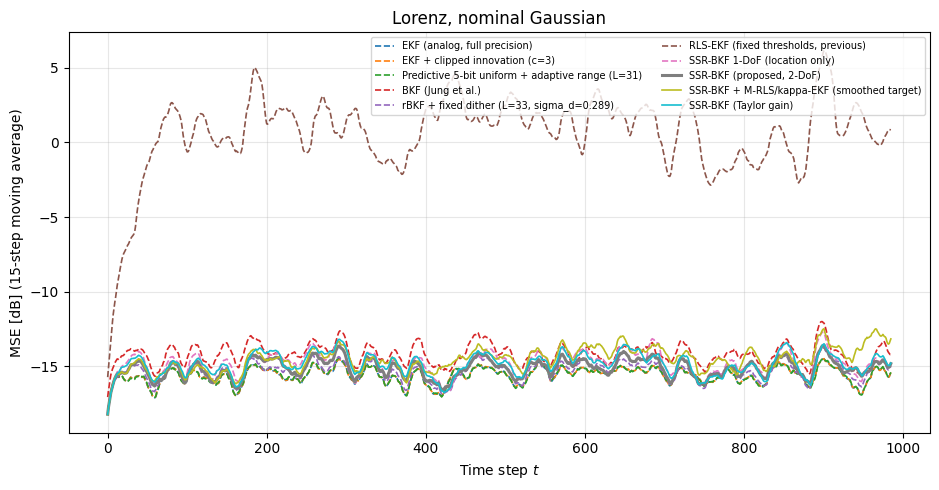

In [8]:
# [Cell 7] 实验 1：Lorenz 标称高斯工况（仅解析方法）
cfg_exp1 = make_config(n_train=400, n_cv=50, n_test=20, T_train=100, T_test=1000,
                       noise='gauss', init_mismatch=0.0, P0='informed', inflate=False)
res1, cur1, runs1 = run_experiment(cfg_exp1, '实验 1: Lorenz 标称高斯', seeds=SEEDS)
ALL_RESULTS['exp1_lorenz_nominal'] = res1
plot_curves(res1, cur1, 'Lorenz, nominal Gaussian')


==================== 实验 2: Lorenz SαS + 失配 ====================
--- seed 0 ---
  EKF (analog, full precision)                          steady    4.39 dB  lost   0.0%
  EKF + clipped innovation (c=3)                        steady   -3.77 dB  lost   0.0%
  Predictive 5-bit uniform + adaptive range (L=31)      steady   -4.36 dB  lost   0.0%
  BKF (Jung et al.)                                     steady   22.07 dB  lost  35.0%
  rBKF + fixed dither (L=33, sigma_d=0.289)             steady   20.56 dB  lost  20.0%
  RLS-EKF (fixed thresholds, previous)                  steady   16.12 dB  lost   0.0%
  SSR-BKF 1-DoF (location only)                         steady   23.21 dB  lost  55.0%
  SSR-BKF (proposed, 2-DoF)                             steady   -0.41 dB  lost   0.0%
  SSR-BKF + M-RLS/kappa-EKF (smoothed target)           steady   -1.12 dB  lost   0.0%
  SSR-BKF (Taylor gain)                                 steady   -6.28 dB  lost   0.0%

>>> 训练 KalmanNet (analog, full precision) (参数量 23

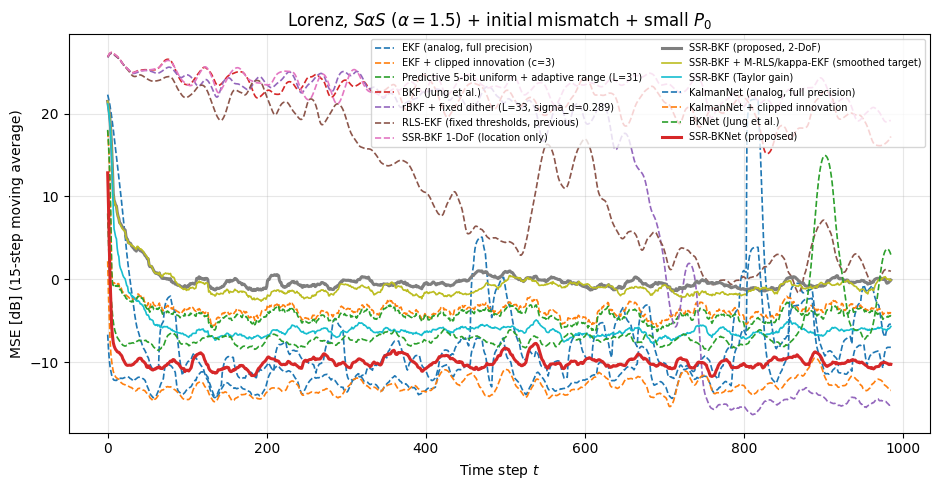

In [9]:
# [Cell 8] 实验 2：Lorenz + SαS(α=1.5) 脉冲噪声 + 初始失配 + P0=small
#          解析方法开启协方差匹配 (inflate=True)；学习类方法与解析方法共用同一份测试数据
cfg_exp2 = make_config(n_train=400, n_cv=50, n_test=20, T_train=100, T_test=1000,
                       noise='sas', alpha=1.5, init_mismatch=2.0, P0='small', inflate=True,
                       iters=300, batch=32, lr=1e-3, cv_every=50, clip_grad=10.0,
                       st_grad=True, ste_mode='unit', learn_w=True,
                       loss_mode='eval', dec_scale='aperture', ap_mult=(1e-2, 1e2))
res2, cur2, runs2 = run_experiment(cfg_exp2, '实验 2: Lorenz SαS + 失配',
                                   learned=['knet', 'knet_clip', 'bknet', 'ssrbknet'], seeds=SEEDS)
ALL_RESULTS['exp2_lorenz_sas'] = res2
plot_curves(res2, cur2, r'Lorenz, $S\alpha S$ ($\alpha=1.5$) + initial mismatch + small $P_0$')


==================== 实验 3: 多普勒 SαS + 失配 ====================
--- seed 0 ---
  EKF (analog, full precision)                          steady   31.18 dB  lost  15.0%
  EKF + clipped innovation (c=3)                        steady  -18.58 dB  lost   0.0%
  Predictive 5-bit uniform + adaptive range (L=31)      steady  -18.74 dB  lost   0.0%
  BKF (Jung et al.)                                     steady   18.58 dB  lost  20.0%
  rBKF + fixed dither (L=33, sigma_d=0.183)             steady   10.92 dB  lost   5.0%
  RLS-EKF (fixed thresholds, previous)                  steady    8.13 dB  lost   5.0%
  SSR-BKF 1-DoF (location only)                         steady   19.57 dB  lost  40.0%
  SSR-BKF (proposed, 2-DoF)                             steady  -17.35 dB  lost   0.0%
  SSR-BKF + M-RLS/kappa-EKF (smoothed target)           steady  -17.31 dB  lost   0.0%
  SSR-BKF (Taylor gain)                                 steady  -16.60 dB  lost   0.0%

>>> 训练 KalmanNet (analog, full precision) (参数量 12943

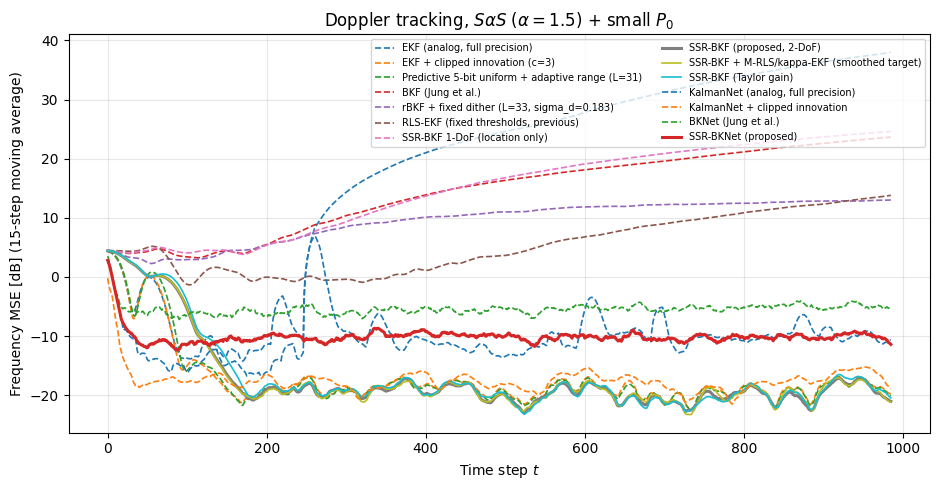

In [10]:
# [Cell 9] 实验 3：机动多普勒线谱 I/Q 跟踪 (SαS α=1.5 + 初始失配 + P0=small，关闭协方差膨胀)
#          网络：相位解调投影 + 全状态加权监督；孔径限制在 [0.5, 2]×a0、解码尺度固定（沿用原设置）
cfg_dop = make_config(scenario='doppler',
                      n_train=400, n_cv=50, n_test=20, T_train=120, T_test=1000,
                      noise='sas', alpha=1.5, dop_r2=0.04, dop_qf=1e-4, dop_qfd=5e-3,
                      init_mismatch=1.0, P0='small', inflate=False,
                      iters=300, batch=32, lr=1e-3, cv_every=50,
                      st_grad=False, learn_w=False,
                      loss_mode='full', state_w=[1.0, 2.0, 1.0], phase_demod=True,
                      dec_scale='fixed', ap_mult=(0.5, 2.0))
res3, cur3, runs3 = run_experiment(cfg_dop, '实验 3: 多普勒 SαS + 失配',
                                   learned=['knet', 'knet_clip', 'bknet', 'ssrbknet'], seeds=SEEDS)
ALL_RESULTS['exp3_doppler_sas'] = res3
plot_curves(res3, cur3, r'Doppler tracking, $S\alpha S$ ($\alpha=1.5$) + small $P_0$', ylabel='Frequency MSE [dB]')

In [11]:
# [Cell 10] 实验 4：学习类滤波器消融（耗时较长，可按需删减 learned 列表）
# 4a) Lorenz：直通梯度 none / unit / soft
LEARNED_SPECS.update({
    'ssrbknet_ste_none': dict(kind='ssrbknet', st_grad=False, label='SSR-BKNet (no STE)'),
    'ssrbknet_ste_unit': dict(kind='ssrbknet', st_grad=True, ste_mode='unit', label='SSR-BKNet (unit STE)'),
    'ssrbknet_ste_soft': dict(kind='ssrbknet', st_grad=True, ste_mode='soft', label='SSR-BKNet (soft STE)'),
})
res4a, cur4a, _ = run_experiment(cfg_exp2, '实验 4a: Lorenz 直通梯度消融', analytic=[],
                                 learned=['ssrbknet_ste_none', 'ssrbknet_ste_unit', 'ssrbknet_ste_soft'],
                                 seeds=SEEDS)
ALL_RESULTS['exp4a_ste'] = res4a

# 4b) Doppler：相位解调 × 全状态监督 (2×2)，另加直通梯度与"孔径随动"解码
LEARNED_SPECS.update({
    'dop_pd1_full': dict(kind='ssrbknet', phase_demod=True, loss_mode='full', label='SSR-BKNet (demod, full loss)'),
    'dop_pd1_freq': dict(kind='ssrbknet', phase_demod=True, loss_mode='eval', label='SSR-BKNet (demod, freq loss)'),
    'dop_pd0_full': dict(kind='ssrbknet', phase_demod=False, loss_mode='full', label='SSR-BKNet (no demod, full loss)'),
    'dop_pd0_freq': dict(kind='ssrbknet', phase_demod=False, loss_mode='eval', label='SSR-BKNet (no demod, freq loss)'),
    'dop_freq_ste': dict(kind='ssrbknet', phase_demod=True, loss_mode='eval', st_grad=True, ste_mode='unit',
                         label='SSR-BKNet (demod, freq loss, unit STE)'),
    'dop_aperture': dict(kind='ssrbknet', dec_scale='aperture', ap_mult=(0.5, 25.0),
                         label='SSR-BKNet (demod, full loss, adaptive decode scale)'),
})
res4b, cur4b, _ = run_experiment(cfg_dop, '实验 4b: 多普勒消融', analytic=[],
                                 learned=['dop_pd1_full', 'dop_pd1_freq', 'dop_pd0_full', 'dop_pd0_freq',
                                          'dop_freq_ste', 'dop_aperture'],
                                 seeds=SEEDS)
ALL_RESULTS['exp4b_doppler_ablation'] = res4b


==================== 实验 4a: Lorenz 直通梯度消融 ====================
--- seed 0 ---

>>> 训练 SSR-BKNet (no STE) (参数量 25596, st_grad=False, ste=unit, loss=eval)
    [SSR-BKNet (no STE)] it    50  train   31.60 dB  cv   31.09 dB  (best   31.09 dB, skipped 1, 41 s)
    [SSR-BKNet (no STE)] it   100  train   42.02 dB  cv   41.54 dB  (best   31.09 dB, skipped 1, 81 s)
    [SSR-BKNet (no STE)] it   150  train   47.19 dB  cv   47.20 dB  (best   31.09 dB, skipped 1, 122 s)
    [SSR-BKNet (no STE)] it   200  train   43.76 dB  cv   43.25 dB  (best   31.09 dB, skipped 2, 165 s)
    [SSR-BKNet (no STE)] it   250  train   13.39 dB  cv   12.70 dB  (best   12.70 dB, skipped 3, 205 s)
    [SSR-BKNet (no STE)] it   300  train   40.15 dB  cv   40.08 dB  (best   12.70 dB, skipped 3, 247 s)
*** SSR-BKNet (no STE)                                  steady   -6.58 dB  lost   0.0%

>>> 训练 SSR-BKNet (unit STE) (参数量 25596, st_grad=True, ste=unit, loss=eval)
    [SSR-BKNet (unit STE)] it    50  train    6.20 dB  cv    

In [12]:
# [Cell 11] 实验 5：硬件失配下盲自适应闭环的价值（Lorenz 标称高斯，仅解析方法）
#           失配只作用在比较器阵列上，解码端仍按标称参数；比较固定参数与 M-RLS/kappa-EKF（门控开/关）
ADAPT_METHODS = ['ssrbkf', 'ssrbkf_rls', 'ssrbkf_taylor']
res5 = {}
for k_mis, thr_b in ((1.0, 0.0), (1.5, 0.0), (2.0, 0.0), (0.5, 0.0), (1.0, 0.3)):
    for gate in (True, False):
        tag = f'kappa×{k_mis:g}, thr_bias={thr_b:g}, gate={"on" if gate else "off"}'
        cfg5 = make_config(n_train=400, n_cv=50, n_test=20, T_train=100, T_test=1000,
                           noise='gauss', init_mismatch=0.0, P0='informed', inflate=False,
                           kappa_mismatch=k_mis, thr_bias=thr_b, adapt_gate=gate)
        r5, _, _ = run_experiment(cfg5, f'实验 5: {tag}',
                                  analytic=ADAPT_METHODS if gate else ['ssrbkf_rls'], seeds=SEEDS)
        res5[tag] = r5
ALL_RESULTS['exp5_hardware_mismatch'] = res5

print('\n==== 实验 5 汇总：稳态 MSE [dB] ====')
for tag, r5 in res5.items():
    print(f'{tag:<44s}' + '  '.join(f'{k}: {v["steady_db"]:7.2f}' for k, v in r5.items()))

# 盲自适应在多普勒场景的门控效果（原实验中无门控时失锁）
for gate in (True, False):
    cfg_g = with_seed(cfg_dop, cfg_dop.seed)
    cfg_g.adapt_gate = gate
    r_g, _, _ = run_experiment(cfg_g, f'实验 5b: 多普勒 M-RLS/kappa-EKF, gate={"on" if gate else "off"}',
                               analytic=['ssrbkf', 'ssrbkf_rls'], seeds=SEEDS)
    ALL_RESULTS[f'exp5b_doppler_gate_{"on" if gate else "off"}'] = r_g


==================== 实验 5: kappa×1, thr_bias=0, gate=on ====================
--- seed 0 ---
  SSR-BKF (proposed, 2-DoF)                             steady  -15.03 dB  lost   0.0%
  SSR-BKF + M-RLS/kappa-EKF (smoothed target)           steady  -14.35 dB  lost   0.0%
  SSR-BKF (Taylor gain)                                 steady  -14.75 dB  lost   0.0%

==== 实验 5: kappa×1, thr_bias=0, gate=on  [1 个种子] ====
Method                                                     MSE   trans  steady  median     p90  lost%  time/s
-------------------------------------------------------------------------------------------------------------
SSR-BKF (proposed, 2-DoF)                               -15.08  -15.61  -15.03  -21.59  -16.31    0.0     5.5
SSR-BKF + M-RLS/kappa-EKF (smoothed target)             -14.46  -15.51  -14.35  -21.01  -15.60    0.0     8.0
SSR-BKF (Taylor gain)                                   -14.81  -15.36  -14.75  -21.29  -15.97    0.0     6.0

==================== 实验 5: kappa×1, thr_

In [13]:
# [Cell 12] 汇总与保存
for name, r in ALL_RESULTS.items():
    if r and all(isinstance(v, dict) and 'label' in v for v in r.values()):
        print_table(r, name, show_std=len(SEEDS) > 1)

with open('ssr_bknet_results.json', 'w', encoding='utf-8') as fh:
    json.dump(dict(seeds=list(SEEDS), results=ALL_RESULTS), fh, ensure_ascii=False, indent=2)
print('\n结果已保存到 ssr_bknet_results.json')


==== exp1_lorenz_nominal ====
Method                                                     MSE   trans  steady  median     p90  lost%  time/s
-------------------------------------------------------------------------------------------------------------
EKF (analog, full precision)                            -15.59  -16.07  -15.54  -21.99  -16.82    0.0     3.2
EKF + clipped innovation (c=3)                          -15.59  -16.06  -15.54  -21.99  -16.82    0.0     5.7
Predictive 5-bit uniform + adaptive range (L=31)        -15.58  -16.06  -15.53  -21.98  -16.82    0.0     5.8
BKF (Jung et al.)                                       -14.15  -14.61  -14.10  -20.83  -15.36    0.0     3.5
rBKF + fixed dither (L=33, sigma_d=0.289)               -15.29  -15.71  -15.25  -21.77  -16.50    0.0     3.5
RLS-EKF (fixed thresholds, previous)                      1.14   -1.50    1.35   -7.62   -0.37    0.0     3.5
SSR-BKF 1-DoF (location only)                           -14.74  -15.23  -14.69  -21.31  -